In [70]:
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow import keras


In [71]:
np.random.seed(42)
tf.random.set_seed(42)


In [72]:
WINDOW = 30
RUL_CAP = 30
COLUMNS = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
SENSORS = ["s2", "s3", "s4", "s7", "s8", "s9", "s11",
           "s12", "s13", "s14", "s15", "s17", "s20", "s21"]



In [73]:
train = pd.read_csv("train_FD001.txt", sep=r"\s+", header=None)
test = pd.read_csv("test_FD001.txt", sep=r"\s+", header=None)
train = train.dropna(axis=1, how="all")
test = test.dropna(axis=1, how="all")
train.columns = COLUMNS
test.columns = COLUMNS
true_rul = pd.read_csv("RUL_FD001.txt", header=None)[0].to_numpy()

In [74]:
last_cycle   = train.groupby("unit")["cycle"].transform("max")
train["RUL"] = (last_cycle - train["cycle"]).clip(upper=RUL_CAP)

In [75]:
s_min = train[SENSORS].min()
s_max = train[SENSORS].max()
train[SENSORS] = (train[SENSORS] - s_min) / (s_max - s_min)
test[SENSORS] = (test[SENSORS] - s_min) / (s_max - s_min)


In [76]:
X_train, y_train, engine_id = [], [], []
for unit, grp in train.groupby("unit"):
    values = grp[SENSORS].to_numpy(dtype="float32")
    labels = grp["RUL"].to_numpy(dtype="float32")
    for end in range(WINDOW, len(values) + 1):
        X_train.append(values[end - WINDOW:end])
        y_train.append(labels[end - 1])
        engine_id.append(unit)
X_train = np.array(X_train)
y_train = np.array(y_train)
engine_id = np.array(engine_id)


In [77]:
X_test = []
for unit, grp in test.groupby("unit"):
    values = grp[SENSORS].to_numpy(dtype="float32")
    X_test.append(values[-WINDOW:])
X_test = np.array(X_test)
y_test = np.minimum(true_rul, RUL_CAP)

print(X_train.shape)
print(X_test.shape)


(17731, 30, 14)
(100, 30, 14)


In [78]:
train_mask = engine_id<= 80
X_tr, y_tr = X_train[train_mask], y_train[train_mask]
X_val, y_val = X_train[~train_mask], y_train[~train_mask]

model = keras.Sequential([
    keras.Input(shape=(WINDOW, len(SENSORS))),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1),
])
model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                        │ (None, 30, 64)              │          20,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 33,729 (131.75 KB)

 Trainable params: 33,729 (131.75 KB)

 Non-trainable params: 0 (0.00 B)

In [79]:

history = model.fit(
    X_tr, y_tr / RUL_CAP,
    validation_data=(X_val, y_val / RUL_CAP),
    epochs=60,
    batch_size=256,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)
    ],
    verbose=2
)
model.save("CMAPSS.keras")


Epoch 1/60
54/54 - 5s - 85ms/step - loss: 0.0969 - val_loss: 0.0143 - learning_rate: 0.0010
Epoch 2/60
54/54 - 2s - 44ms/step - loss: 0.0225 - val_loss: 0.0116 - learning_rate: 0.0010
Epoch 3/60
54/54 - 2s - 44ms/step - loss: 0.0179 - val_loss: 0.0111 - learning_rate: 0.0010
Epoch 4/60
54/54 - 3s - 47ms/step - loss: 0.0147 - val_loss: 0.0059 - learning_rate: 0.0010
Epoch 5/60
54/54 - 3s - 51ms/step - loss: 0.0108 - val_loss: 0.0063 - learning_rate: 0.0010
Epoch 6/60
54/54 - 2s - 44ms/step - loss: 0.0087 - val_loss: 0.0067 - learning_rate: 0.0010
Epoch 7/60
54/54 - 2s - 40ms/step - loss: 0.0079 - val_loss: 0.0075 - learning_rate: 0.0010
Epoch 8/60
54/54 - 2s - 41ms/step - loss: 0.0070 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 9/60
54/54 - 2s - 43ms/step - loss: 0.0063 - val_loss: 0.0088 - learning_rate: 0.0010
Epoch 10/60
54/54 - 2s - 43ms/step - loss: 0.0056 - val_loss: 0.0084 - learning_rate: 5.0000e-04
Epoch 11/60
54/54 - 2s - 44ms/step - loss: 0.0053 - val_loss: 0.0078 - lear

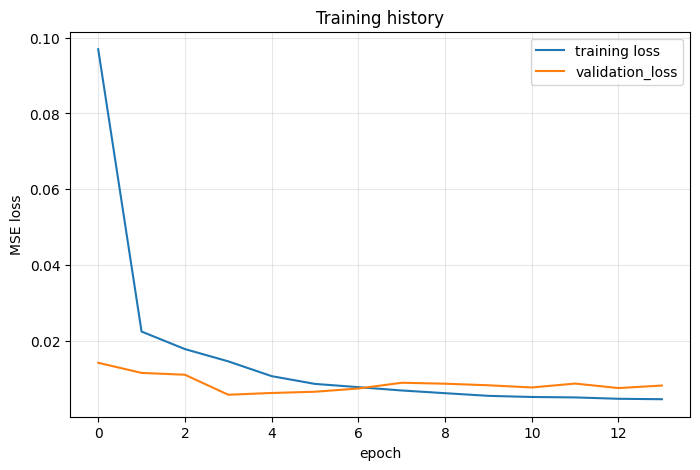

In [80]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation_loss")
plt.xlabel("epoch");
plt.ylabel("MSE loss");
plt.legend();
plt.grid(alpha=0.3)
plt.title("Training history")
plt.show()


In [81]:
y_pred = model.predict(X_test, verbose=0).ravel() * RUL_CAP

rmse = np.sqrt(np.mean((y_pred - y_test) **2))
mae = np.mean(np.mean(y_pred - y_test))
d = y_pred - y_test
nasa_score = np.sum(np.where(d<0, np.exp(-2 / 13) -1, np.exp(d/10) - 1))
print(f"Test RMSE : {rmse:6.2f} cycles")
print(f"Test MAE : {mae:6.2f} cycles")
print(f" NASA score: {nasa_score:6.1f} (lower is better)")


Test RMSE :   2.78 cycles
Test MAE :   0.06 cycles
 NASA score:    1.2 (lower is better)


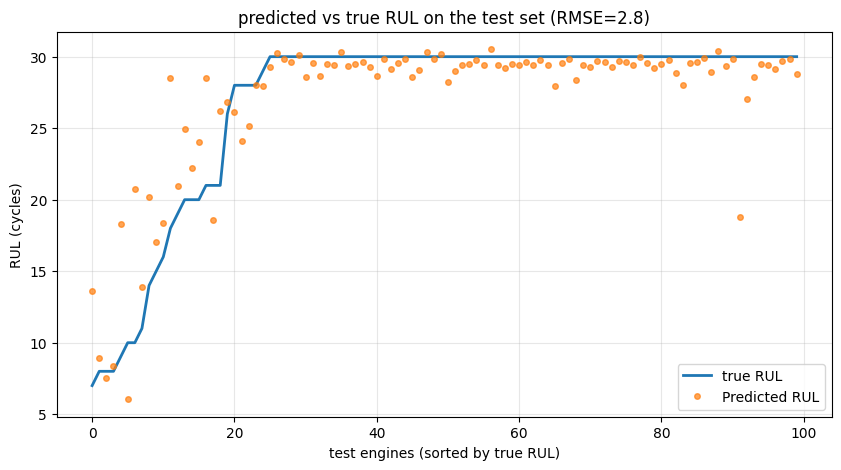

In [82]:
order = np.argsort(y_test)
plt.figure(figsize=(10,5))
plt.plot(y_test[order], lw=2, label="true RUL")
plt.plot(y_pred[order], "o", ms=4, alpha=0.7, label="Predicted RUL")
plt.xlabel("test engines (sorted by true RUL)");
plt.ylabel("RUL (cycles)")
plt.legend();
plt.grid(alpha=0.3)
plt.title(f"predicted vs true RUL on the test set (RMSE={rmse:.1f})")
plt.show()

In [83]:
import shap
background = X_train[np.random.choice(len(X_train), 100, replace=False)]
explain = X_test[:50]
explainer = shap.GradientExplainer(model, background)
shap_values = np.array(explainer.shap_values(explain))
if shap_values.ndim == 4:
    shap_values = shap_values[..., 0]
shap_values = shap_values*RUL_CAP

C:\Users\lenovo\miniconda3\Lib\site-packages\keras\src\models\functional.py:258: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_7
Received: inputs=['Tensor(shape=(50, 30, 14))']
  warnings.warn(msg)


In [84]:
importance = np.abs(shap_values).mean(axis=(0,1))
order = np.argsort(importance)

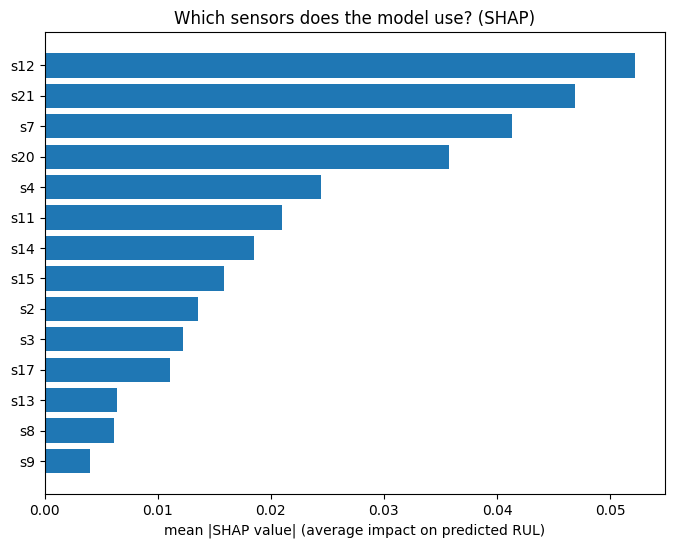

In [85]:
plt.figure(figsize=(8,6))
plt.barh(np.array(SENSORS)[order], importance[order])
plt.xlabel("mean |SHAP value| (average impact on predicted RUL)")
plt.title("Which sensors does the model use? (SHAP)")
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_28276\2057291200.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values.sum(axis=1),


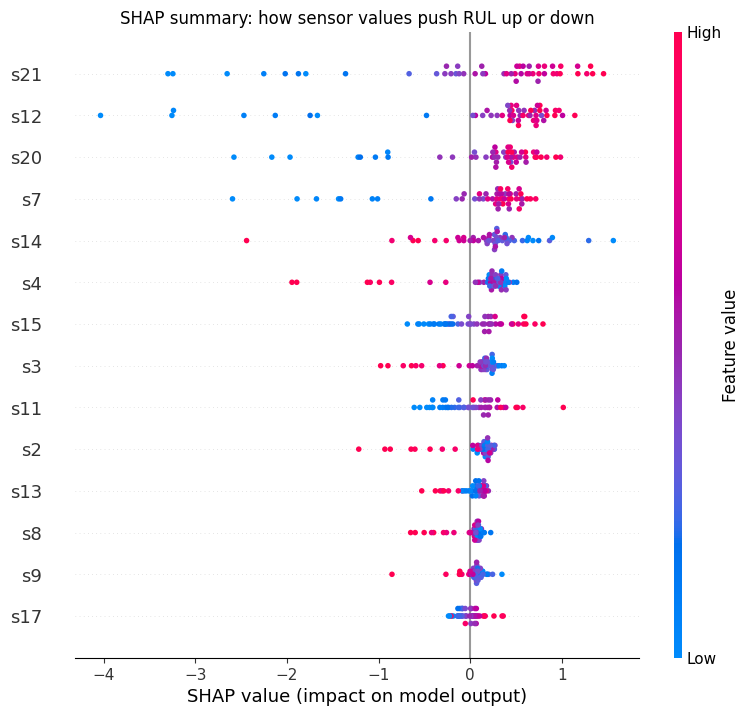

In [86]:
shap.summary_plot(shap_values.sum(axis=1),
                                  explain.mean(axis=1),
                                  feature_names=SENSORS, show=False)
plt.title("SHAP summary: how sensor values push RUL up or down")
plt.show()

In [87]:
top3 = [SENSORS[i] for i in np.argsort(importance)[::-1][:3]]
print(f"Top 3 most important sensors:{top3}")

Top 3 most important sensors:['s12', 's21', 's7']
